# 第6回　深層ニューラルネットワークの訓練技法

講義の 5 つの技法（初期化・正規化・残差接続・Dropout・Weight Decay）を，NumPy で動かして確かめる．

| 節 | テーマ |
|---|---|
| §1 | 初期化と信号の大きさ |
| §2 | 正規化の計算：BatchNorm と LayerNorm |
| §3 | 残差接続と勾配 |
| §4 | Dropout と Weight Decay |
| §5 | 複数シード |
| §6 | （任意）PyTorch の BatchNorm・LayerNorm・Dropout |

```{admonition} この章の使い方
:class: tip
ページ右上のロケットのボタンから Colab で開くか，[環境構築](setup.md) に従って手元で実行する．セルは **上から順に** 実行する．
**やってみよう** は `# TODO` の行を書き換えて再実行する（先に結果を予想してから）．「補助コード」と書いたセルは本題ではない補助の実装で，中身は読まなくてよい（折りたたんである）．
詳しくは [ノートブックの使い方](usage.md)．
```

環境：Python 3 ＋ NumPy ＋ Matplotlib．§6 のみ PyTorch（入っていなければ読み飛ばす）．

In [1]:
import numpy as np
import matplotlib.pyplot as plt
try:
    import matplotlib_fontja                       # 図の日本語フォント（pip install matplotlib-fontja）
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=False)
    import matplotlib_fontja
np.set_printoptions(precision=4, suppress=True)   # 数値を小数 4 桁で表示する

## §1 初期化と信号の大きさ

各層で信号の大きさが $g$ 倍になると，$l$ 層後には $g^l$ 倍になる．まず数だけ確かめる．

In [2]:
for g in (0.85, 1.0, 1.2):
    print(f"g = {g:4.2f}:  6 層後 {g**6:6.2f} 倍,  20 層後 {g**20:8.2f} 倍")

g = 0.85:  6 層後   0.38 倍,  20 層後     0.04 倍
g = 1.00:  6 層後   1.00 倍,  20 層後     1.00 倍
g = 1.20:  6 層後   2.99 倍,  20 層後    38.34 倍


次に，本物のネットワークで見る．入力 784 次元・隠れ層 256 ユニット × 20 層（活性化関数 ReLU）に，
分散 1 に標準化した入力を通し，各層の出力の大きさ（2 乗平均の平方根．RMS）を測る．重みの初期化を 3 通り比べる．

- `normal`：$\mathcal{N}(0, 1)$（分散 1．大きすぎる）
- `lecun`：$\sigma_w^2 = 1/N$（LeCun）
- `he`：$\sigma_w^2 = 2/N$（He．ReLU 向け）

In [3]:
def rms(z):
    """大きさ：2 乗平均の平方根（root mean square）．"""
    return np.sqrt(np.mean(z ** 2))

def signal_size_by_layer(init, n_in=784, n_hidden=256, depth=20, n_samples=256, seed=0):
    """init で初期化した depth 層の ReLU ネットワークに入力を通し，各層の出力の大きさ（RMS）を返す．"""
    rng = np.random.default_rng(seed)
    z = rng.normal(0.0, 1.0, (n_samples, n_in))          # 入力：平均 0・分散 1
    sizes = [rms(z)]
    n_prev = n_in
    for l in range(depth):
        std_w = {'normal': 1.0, 'lecun': np.sqrt(1.0 / n_prev), 'he': np.sqrt(2.0 / n_prev)}[init]   # 名前から重みの標準偏差を引く
        W = rng.normal(0.0, std_w, (n_hidden, n_prev))     # 重み：平均 0，標準偏差 std_w
        z = np.maximum(0.0, z @ W.T)                       # 線形 → ReLU（バイアスは 0）
        sizes.append(rms(z))
        n_prev = n_hidden
    return np.array(sizes)

for init in ('normal', 'lecun', 'he'):
    sizes = signal_size_by_layer(init)
    print(f"{init:7s}: 層 0, 5, 10, 15, 20 の出力の大きさ =", sizes[[0, 5, 10, 15, 20]])   # [...] で 5 つの層だけ取り出す

normal : 層 0, 5, 10, 15, 20 の出力の大きさ = [1.0012e+00 3.5123e+05 6.3437e+10 8.5899e+15 1.2101e+21]
lecun  : 層 0, 5, 10, 15, 20 の出力の大きさ = [1.0012 0.1914 0.033  0.0043 0.0006]
he     : 層 0, 5, 10, 15, 20 の出力の大きさ = [1.0012 1.0828 1.055  0.7707 0.5857]


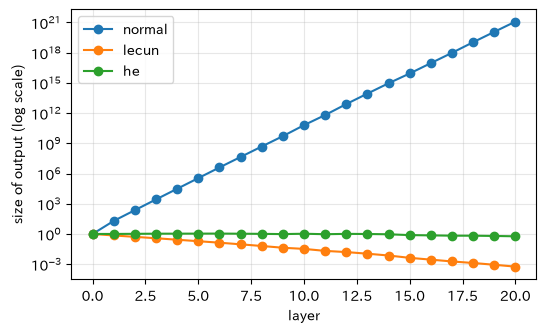

In [4]:
plt.figure(figsize=(6, 3.5))
for init in ('normal', 'lecun', 'he'):
    plt.semilogy(signal_size_by_layer(init), marker='o', label=init)
plt.xlabel('layer'); plt.ylabel('size of output (log scale)'); plt.legend(); plt.grid(alpha=0.3); plt.show()

読み方：`normal` では 10 層で $10^{10}$ を超える（爆発）．`lecun` では ReLU が負の半分を 0 にするぶん，出力の 2 乗平均が総入力の分散の半分になり，層ごとに約 $1/\sqrt{2}$ 倍（20 層で約 1/1,000）に縮む．`he` では重みの分散を 2 倍にしてこれを補うので，20 層後も 1 前後に保たれる（の「$N\sigma_w^2 \approx 1$」が狙い．幅が有限なので，層ごとに少しゆらぐ）．

**やってみよう 1-1**　入力 784 個の層で He の初期化を使うと，重みの標準偏差はいくらか．先に手で計算してから，下のセルで確かめる．

In [5]:
N = 784   # TODO: 入力の数を変えてみる（256 や 1024）
print("He の初期化の標準偏差 sqrt(2/N) =", np.sqrt(2.0 / N))
print("N(0,1) で初期化したときの第 1 層の総入力の標準偏差 ≈ sqrt(N) =", np.sqrt(N))

He の初期化の標準偏差 sqrt(2/N) = 0.050507627227610534
N(0,1) で初期化したときの第 1 層の総入力の標準偏差 ≈ sqrt(N) = 28.0


**やってみよう 1-2**　深さを 50 層にすると，`lecun` の 50 層後の大きさはいくらになるか．`he` は保たれるか．

In [6]:
depth = 20   # TODO: 50 に変えて実行する
for init in ('lecun', 'he'):
    print(f"{init:6s}: {depth} 層後の大きさ = {signal_size_by_layer(init, depth=depth)[-1]:.4g}")

lecun : 20 層後の大きさ = 0.000572
he    : 20 層後の大きさ = 0.5857


## §2 正規化の計算：BatchNorm と LayerNorm講義の数値例．値 $1, 3, 5, 7$ を，平均 0・分散 1 にそろえる（$\epsilon = 0$，$\gamma = 1$，$\beta = 0$）．

In [7]:
u = np.array([1.0, 3.0, 5.0, 7.0])
mu, var = u.mean(), u.var()
u_hat = (u - mu) / np.sqrt(var)
print("平均 =", mu, " 分散 =", var)
print("正規化した値 =", u_hat)
print("正規化した値の平均 =", u_hat.mean(), " 分散 =", u_hat.var())      #講義のクイズ：0 と 1

平均 = 4.0  分散 = 5.0
正規化した値 = [-1.3416 -0.4472  0.4472  1.3416]
正規化した値の平均 = 0.0  分散 = 1.0


BatchNorm と LayerNorm の違いは「どの軸で平均と分散をとるか」．$M = 4$ 個のサンプル × $d = 3$ 個の特徴の表で確かめる．
NumPy では `axis=0` が列ごと（サンプル方向にまとめる＝BatchNorm），`axis=1` が行ごと（特徴方向にまとめる＝LayerNorm）．

In [8]:
def normalize(U, axis, eps=1e-5):
    mu = U.mean(axis=axis, keepdims=True)
    var = U.var(axis=axis, keepdims=True)
    return (U - mu) / np.sqrt(var + eps)

U = np.array([[1.0, 10.0, 100.0],        # 1 行が 1 サンプル，1 列が 1 つの特徴（ユニット）
              [3.0, 20.0, 200.0],
              [5.0, 30.0, 300.0],
              [7.0, 40.0, 400.0]])
bn = normalize(U, axis=0)    # BatchNorm：列（特徴）ごとに，4 サンプルで統計をとる
ln = normalize(U, axis=1)    # LayerNorm：行（サンプル）ごとに，3 特徴で統計をとる
print("BatchNorm（列ごと）\n", bn)
print("列ごとの平均 =", bn.mean(axis=0), " 行ごとの平均 =", bn.mean(axis=1))
print("LayerNorm（行ごと）\n", ln)
print("列ごとの平均 =", ln.mean(axis=0), " 行ごとの平均 =", ln.mean(axis=1))

BatchNorm（列ごと）
 [[-1.3416 -1.3416 -1.3416]
 [-0.4472 -0.4472 -0.4472]
 [ 0.4472  0.4472  0.4472]
 [ 1.3416  1.3416  1.3416]]
列ごとの平均 = [0. 0. 0.]  行ごとの平均 = [-1.3416 -0.4472  0.4472  1.3416]
LayerNorm（行ごと）
 [[-0.8054 -0.604   1.4094]
 [-0.8003 -0.6096  1.4099]
 [-0.7986 -0.6114  1.4101]
 [-0.7978 -0.6124  1.4102]]
列ごとの平均 = [-0.8005 -0.6094  1.4099]  行ごとの平均 = [ 0.  0. -0.  0.]


読み方：BatchNorm の結果は列ごとの平均が 0（行ごとは 0 ではない）．LayerNorm は行ごとの平均が 0．
第 1 列（1, 3, 5, 7）の BatchNorm の結果が，上の数値例と同じになっていることも確かめる．

**やってみよう 2-1**　サンプルが 1 個しかないとき（`U[:1]`），BatchNorm は計算できるか．LayerNorm は？

In [9]:
U1 = U[:1]   # サンプル 1 個だけ
print("BatchNorm:", normalize(U1, axis=0))   # 分散 0 → eps で割るので全部 0 になる（意味のない値）
print("LayerNorm:", normalize(U1, axis=1))   # 1 サンプルの中で計算できる

BatchNorm: [[0. 0. 0.]]
LayerNorm: [[-0.8054 -0.604   1.4094]]


BatchNorm はバッチの他のサンプルに依存する（1 個では統計がとれない）．LayerNorm はサンプルごとに閉じているので，バッチサイズによらない．これが Transformer で LayerNorm を使う理由．

## §3 残差接続と勾配講義の 2 次元の例．$F$ のヤコビ行列 $J_F$ と上の層から来た勾配 $\nabla_{\boldsymbol{y}} L = (1, 1)^\top$ から，下の層へ渡す勾配を求める．

In [10]:
J_F = np.array([[0.1, 0.2],
                [0.0, -0.3]])
g_y = np.array([1.0, 1.0])
I = np.eye(2)
g_plain = J_F.T @ g_y             # 残差接続なし：y = F(z)
g_res = (I + J_F).T @ g_y         # 残差接続あり：y = z + F(z)
print("残差接続なし:", g_plain, " 大きさ =", np.linalg.norm(g_plain))
print("残差接続あり:", g_res, " 大きさ =", np.linalg.norm(g_res))

残差接続なし: [ 0.1 -0.1]  大きさ = 0.1414213562373095
残差接続あり: [1.1 0.9]  大きさ = 1.4212670403551895


次に，ブロックを 30 個積む．各ブロックの $J_F$ は毎回違うランダムな小さい行列（要素の標準偏差 0.1）とし，
一番上の勾配 $(1,1)^\top$ が一番下まで伝わるときの大きさを，残差接続あり・なしで比べる（の「30 ブロック」）．

30 ブロック下での勾配の大きさ：なし = 7.26e-27,  あり = 2.61


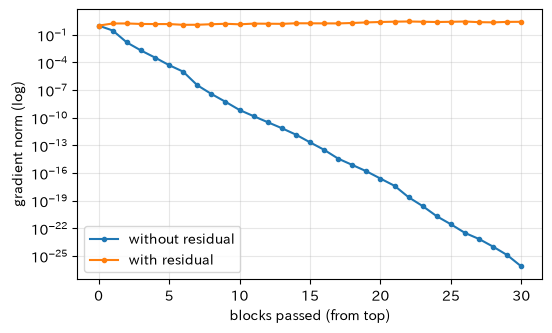

In [11]:
rng = np.random.default_rng(0)
n_blocks = 30
Js = [rng.normal(0.0, 0.1, (2, 2)) for _ in range(n_blocks)]
g_plain, g_res = g_y.copy(), g_y.copy()
norms_plain, norms_res = [1.0], [1.0]
for J in reversed(Js):                        # 上のブロックから順に下へ
    g_plain = J.T @ g_plain
    g_res = (I + J).T @ g_res
    norms_plain.append(np.linalg.norm(g_plain)); norms_res.append(np.linalg.norm(g_res))
print(f"30 ブロック下での勾配の大きさ：なし = {norms_plain[-1]:.2e},  あり = {norms_res[-1]:.2f}")
plt.figure(figsize=(6, 3.5))
plt.semilogy(norms_plain, marker='.', label='without residual')
plt.semilogy(norms_res, marker='.', label='with residual')
plt.xlabel('blocks passed (from top)'); plt.ylabel('gradient norm (log)'); plt.legend(); plt.grid(alpha=0.3); plt.show()

読み方：残差接続なしでは，小さい $J_F$ が 30 回掛かって勾配が約 $7 \times 10^{-27}$（$10^{-26}$ 程度）まで消える．ありでは $(I + J_F)$ の $I$ のおかげで，同じ桁の大きさ（この例では約 2.6）のまま下まで届く．
「上」は出力側（損失に近い側），「下」は入力側．大きさはユークリッドノルム $\sqrt{g_1^2 + g_2^2}$．

**やってみよう 3-1**　$J_F$ の要素の標準偏差を 0.1 から 0.8 に大きくすると，残差接続ありの勾配はどうなるか（ヒント：$I + J_F$ が 1 より大きくなることもある）．

In [12]:
scale = 0.1   # TODO: 0.8 に変えて実行する．さらに 1.5 にしてみる
rng = np.random.default_rng(0)
g = g_y.copy()
for _ in range(n_blocks):
    g = (I + rng.normal(0.0, scale, (2, 2))).T @ g
print(f"J_F の要素の標準偏差 {scale}：残差接続ありで 30 ブロック下の大きさ = {np.linalg.norm(g):.3g}")

J_F の要素の標準偏差 0.1：残差接続ありで 30 ブロック下の大きさ = 2.11


$J_F$ が大きいと，残差接続があっても勾配は爆発しうる．実際のモデルでは，正規化（§2）と初期化（§1）で $F$ を小さく保ち，残差接続と組み合わせる（のブロック）．

## §4 Dropout と Weight Decay

過学習する状況を作る：訓練データ 40 点（2 クラス，ラベルの約 15% をわざと間違えてある）に対して，隠れ層 64 ユニット × 2 層の大きな MLP を訓練する．
検証データ 1,000 点（正しいラベル）で，新しいデータでの損失を測る．

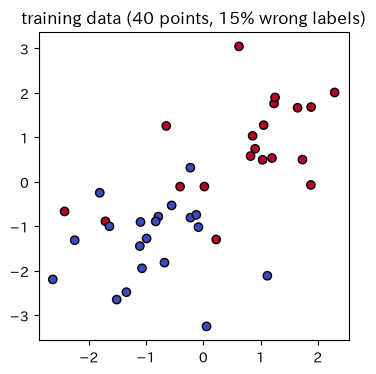

In [13]:
# 補助コード：データを作る関数（中身は読まなくてよい）
def make_blobs(n, seed, flip=0.15):
    """2 クラスのデータ．クラス 0 は (-1,-1) 付近，クラス 1 は (1,1) 付近．各ラベルを確率 flip で反転する．"""
    rng = np.random.default_rng(seed)
    y = rng.integers(0, 2, n)
    X = rng.normal(0.0, 1.0, (n, 2)) + np.where(y[:, None] == 1, 1.0, -1.0)
    wrong = rng.random(n) < flip
    y_noisy = np.where(wrong, 1 - y, y)
    return X, y_noisy

Xtr, ytr = make_blobs(40, seed=1, flip=0.15)        # 訓練：40 点，約 15% のラベルが間違い
Xva, yva = make_blobs(1000, seed=2, flip=0.0)       # 検証：1,000 点，正しいラベル
plt.figure(figsize=(4, 4))
plt.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap='coolwarm', edgecolor='k')
plt.title('training data (40 points, 15% wrong labels)'); plt.show()

In [14]:
# 補助コード：全結合ネットワーク（中身は読まなくてよい．第3回 §3 の mlp_forward/mlp_backward と同じ計算に，
#       初期化の種類・Dropout・Weight Decay を足したもの）
class MLP:
    def __init__(self, sizes, seed=0, init='he', dropout=0.0):
        self.rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            std = {'he': np.sqrt(2.0 / n_in), 'lecun': np.sqrt(1.0 / n_in), 'normal': 1.0}[init]
            self.W.append(self.rng.normal(0.0, std, (n_out, n_in)))
            self.b.append(np.zeros(n_out))
        self.p = dropout

    def forward(self, X, train=False):
        """順伝播．train=True のときだけ Dropout を掛ける（推論時は全ユニットを使う）．"""
        self.cache = []                       # 逆伝播のために (層への入力, 総入力, Dropout のマスク) を覚える
        z = X
        for l, (W, b) in enumerate(zip(self.W, self.b)):
            u = z @ W.T + b
            mask = None
            if l < len(self.W) - 1:           # 隠れ層：ReLU（＋Dropout）
                z_next = np.maximum(0.0, u)
                if train and self.p > 0:
                    mask = (self.rng.random(z_next.shape) >= self.p) / (1.0 - self.p)   # 残りを 1/(1-p) 倍
                    z_next = z_next * mask
            else:                             # 出力層：ロジット（ソフトマックスの前の値）
                z_next = u
            self.cache.append((z, u, mask))
            z = z_next
        return z

    def loss_and_grads(self, X, y, wd=0.0, train=True):
        """交差エントロピー損失と，全パラメータの勾配．wd は Weight Decay の係数 λ．"""
        logits = self.forward(X, train=train)
        P = softmax(logits)
        M = len(y)
        loss = -np.mean(np.log(P[np.arange(M), y] + 1e-12))
        delta = P.copy(); delta[np.arange(M), y] -= 1.0; delta /= M      # 出力層の誤差信号（予測 − 正解）/M
        gW, gb = [None] * len(self.W), [None] * len(self.W)
        for l in reversed(range(len(self.W))):
            z_in, u, _ = self.cache[l]
            gW[l] = delta.T @ z_in + wd * self.W[l]                        # 勾配 ＋ Weight Decay の項 λw
            gb[l] = delta.sum(axis=0)
            if l > 0:
                delta = delta @ self.W[l]                                  # 1 層下へ伝える
                mask_prev = self.cache[l - 1][2]
                if mask_prev is not None:
                    delta = delta * mask_prev
                delta = delta * (self.cache[l - 1][1] > 0)                 # ReLU の傾き
        return loss, gW, gb

    def step(self, gW, gb, lr):
        for l in range(len(self.W)):
            self.W[l] -= lr * gW[l]
            self.b[l] -= lr * gb[l]

    def predict(self, X):
        return np.argmax(self.forward(X, train=False), axis=1)


def softmax(u):
    e = np.exp(u - u.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def cross_entropy(model, X, y):
    P = softmax(model.forward(X, train=False))
    return -np.mean(np.log(P[np.arange(len(y)), y] + 1e-12))


def train(model, Xtr, ytr, Xva, yva, lr=0.1, epochs=300, wd=0.0):
    """全データで勾配を求めて更新（ミニバッチなし）．各エポックの訓練損失・検証損失・検証正解率を返す．"""
    hist = {'train': [], 'val': [], 'val_acc': []}
    for ep in range(epochs):
        loss, gW, gb = model.loss_and_grads(Xtr, ytr, wd=wd, train=True)
        model.step(gW, gb, lr)
        hist['train'].append(cross_entropy(model, Xtr, ytr))
        hist['val'].append(cross_entropy(model, Xva, yva))
        hist['val_acc'].append(np.mean(model.predict(Xva) == yva))
    return hist

In [15]:
configs = {'none':          dict(dropout=0.0, wd=0.0),
           'weight decay':  dict(dropout=0.0, wd=1e-2),
           'dropout':       dict(dropout=0.3, wd=0.0)}
hists = {}
for name, cfg in configs.items():
    model = MLP([2, 64, 64, 2], seed=0, dropout=cfg['dropout'])
    hists[name] = train(model, Xtr, ytr, Xva, yva, lr=0.1, epochs=400, wd=cfg['wd'])
    h = hists[name]
    print(f"{name:13s}: 訓練損失 {h['train'][-1]:.3f}  検証損失 {h['val'][-1]:.3f}  検証正解率 {h['val_acc'][-1]:.3f}")

none         : 訓練損失 0.083  検証損失 0.617  検証正解率 0.792


weight decay : 訓練損失 0.145  検証損失 0.312  検証正解率 0.852


dropout      : 訓練損失 0.190  検証損失 0.350  検証正解率 0.824


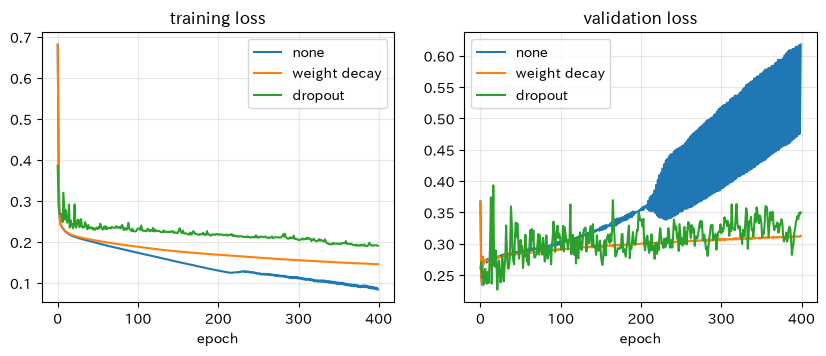

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for name, h in hists.items():
    axes[0].plot(h['train'], label=name); axes[1].plot(h['val'], label=name)
axes[0].set_title('training loss'); axes[1].set_title('validation loss')
for ax in axes:
    ax.set_xlabel('epoch'); ax.grid(alpha=0.3); ax.legend()
plt.show()

読み方：何もしないと（`none`），訓練損失は 0 に近づく一方，検証損失は途中から上がる（間違ったラベルまで覚えている＝過学習）．
Weight Decay と Dropout は，訓練損失を少し高いままにする代わりに，検証損失の上昇を抑える．

**やってみよう 4-1**　$\eta = 0.1$，$\lambda = 0.01$ のとき，勾配が 0 でも重みは 1 回の更新で何倍になるか．1,000 回では？

In [17]:
eta, lam = 0.1, 0.01   # TODO: λ を変えてみる
print("1 回の更新で", 1 - eta * lam, "倍,  1,000 回で", (1 - eta * lam) ** 1000, "倍")

1 回の更新で 0.999 倍,  1,000 回で 0.36769542477096373 倍


**やってみよう 4-2**　Weight Decay の係数 `wd` を 0 から 1.0 まで変えると，訓練損失と検証損失はどうなるか．先に予想してから実行する．

In [18]:
for wd in (0.0, 1e-3, 1e-2, 1e-1, 1.0):   # TODO: 値を足したり変えたりする
    model = MLP([2, 64, 64, 2], seed=0)
    h = train(model, Xtr, ytr, Xva, yva, lr=0.1, epochs=400, wd=wd)
    print(f"wd = {wd:<6g}: 訓練損失 {h['train'][-1]:.3f}  検証損失 {h['val'][-1]:.3f}  検証正解率 {h['val_acc'][-1]:.3f}")

wd = 0     : 訓練損失 0.083  検証損失 0.617  検証正解率 0.792


wd = 0.001 : 訓練損失 0.091  検証損失 0.446  検証正解率 0.838


wd = 0.01  : 訓練損失 0.145  検証損失 0.312  検証正解率 0.852


wd = 0.1   : 訓練損失 0.322  検証損失 0.293  検証正解率 0.912


wd = 1     : 訓練損失 0.693  検証損失 0.693  検証正解率 0.500


読み方：この例では `wd` を大きくするほど検証損失が下がるが，1.0 では重みが縮みすぎて訓練損失も検証損失も高いまま（学習不足）．強さはデータ量に応じて検証データで決める（第7回）．
`wd = 0.1` で訓練損失が検証損失より高いのは，訓練データのラベルの約 15% が間違っているため（それに合わせない方が，正しいラベルの検証データでは良くなる）．

## §5 複数シード

訓練は乱数（初期化，Dropout のマスク）に依存する．同じ設定を種（シード）だけ変えて 5 回訓練し，検証正解率のばらつきを見る．

In [19]:
n_seeds = 5   # TODO（やってみよう 5-1）: 10 に変えて実行する
for name, cfg in configs.items():
    accs = []
    for seed in range(n_seeds):
        model = MLP([2, 64, 64, 2], seed=seed, dropout=cfg['dropout'])
        h = train(model, Xtr, ytr, Xva, yva, lr=0.1, epochs=400, wd=cfg['wd'])
        accs.append(h['val_acc'][-1])
    accs = np.array(accs)
    print(f"{name:13s}: 検証正解率 = {accs}  平均 {accs.mean():.3f} ± 標準偏差 {accs.std():.3f}")

none         : 検証正解率 = [0.792 0.867 0.802 0.789 0.807]  平均 0.811 ± 標準偏差 0.029


weight decay : 検証正解率 = [0.852 0.849 0.835 0.84  0.845]  平均 0.844 ± 標準偏差 0.006


dropout      : 検証正解率 = [0.824 0.821 0.831 0.897 0.847]  平均 0.844 ± 標準偏差 0.028


読み方：1 回の結果の差は，シードによるばらつきと同じ程度のことがある．手法を比べるときは，複数シードの平均とばらつきで比べる（第7回で続ける）．

**やってみよう 5-1**　上のセルの `n_seeds` を 5 から 10 に増やし，平均と標準偏差がどれだけ変わるかを見る．

## §6（任意）PyTorch の BatchNorm・LayerNorm・Dropout

PyTorch では正規化層と Dropout が構成要素として用意されている．**訓練モードと評価モードで計算が変わる**ことを確かめる．

In [20]:
try:
    import torch
    import torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
    print("PyTorch が見つからないので，§6 のセルは何もしない（読み飛ばす）．")

In [21]:
if HAS_TORCH:
    torch.manual_seed(0)
    U_t = torch.tensor(U, dtype=torch.float32)                 # §2 と同じ 4×3 の表
    bn = nn.BatchNorm1d(3, affine=False, eps=1e-5)              # 列（特徴）ごと
    ln = nn.LayerNorm(3, elementwise_affine=False, eps=1e-5)    # 行（サンプル）ごと
    bn.train()
    print("BatchNorm（訓練モード）\n", bn(U_t).detach().numpy())      # §2 の bn と同じ
    print("LayerNorm\n", ln(U_t).detach().numpy())                    # §2 の ln と同じ
    bn.eval()
    print("BatchNorm（評価モード：訓練中に貯めた移動平均で正規化するので，値が違う）\n", bn(U_t).detach().numpy())

BatchNorm（訓練モード）
 [[-1.3416 -1.3416 -1.3416]
 [-0.4472 -0.4472 -0.4472]
 [ 0.4472  0.4472  0.4472]
 [ 1.3416  1.3416  1.3416]]
LayerNorm
 [[-0.8054 -0.604   1.4094]
 [-0.8003 -0.6096  1.4099]
 [-0.7986 -0.6114  1.4101]
 [-0.7978 -0.6124  1.4102]]
BatchNorm（評価モード：訓練中に貯めた移動平均で正規化するので，値が違う）
 [[0.4794 1.7894 1.8366]
 [2.0772 4.1754 4.2854]
 [3.6751 6.5613 6.7343]
 [5.273  8.9472 9.1831]]


In [22]:
if HAS_TORCH:
    drop = nn.Dropout(p=0.5)
    x = torch.ones(8)
    drop.train();  print("訓練モード:", drop(x).numpy())    # 半分が 0，残りは 1/(1-p) = 2 倍
    drop.eval();   print("評価モード:", drop(x).numpy())    # そのまま

訓練モード: [0. 0. 2. 0. 0. 0. 2. 2.]
評価モード: [1. 1. 1. 1. 1. 1. 1. 1.]


`model.train()` と `model.eval()` の切替を忘れると，BatchNorm の統計や Dropout のマスクが推論時にも働き，結果がバッチの構成や乱数に依存する（の注意）．

## §7 補足：実データで訓練技法を比べる（FashionMNIST，8 層の MLP）

§1〜§4 の技法を，実画像（FashionMNIST）と PyTorch の 8 層 MLP で比べる．4 つの設定で同じデータ・同じ学習率・同じ回数だけ訓練し，損失の下がり方とテスト正解率を見る：(a) 小さな乱数で初期化（標準偏差 0.01），(b) He の初期化，(c) He の初期化＋BatchNorm，(d) He の初期化＋残差接続．

```{admonition} 補足節について
:class: note
ここから先は，講義で扱った構造を **実際に学習された本物のモデル** と **実画像** で動かす補足である．[torchvision](https://pytorch.org/vision/) や [Hugging Face Transformers](https://huggingface.co/docs/transformers) から学習済みモデルを取得する（初回はダウンロードに数分かかる．Colab ではインストール不要）．
手元で動かすには `pip install transformers datasets` と，インターネット接続が要る．入っていない環境では，このあとのセルは何もしない．
```

In [23]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TQDM_DISABLE"] = "1"   # ダウンロードの進捗表示を出さない
warnings.filterwarnings("ignore")
try:
    import torch
    import transformers
    import requests
    from PIL import Image
    transformers.logging.set_verbosity_error()
    HAS_HF = True
except ImportError:
    HAS_HF = False
    print("PyTorch か transformers が見つからないので，補足節のセルは何もしない（読み飛ばす）．")

def fetch_image(name):
    """COCO val2017 の画像を取得して PIL の画像で返す（ダウンロードは初回だけ．images/ に保存）"""
    import os
    os.makedirs("images", exist_ok=True)
    path = os.path.join("images", name)
    if not os.path.exists(path):
        r = requests.get("http://images.cocodataset.org/val2017/" + name, timeout=60)
        r.raise_for_status()
        open(path, "wb").write(r.content)
    return Image.open(path).convert("RGB")

COCO_IMAGES = {   # ファイル名: 内容
    "000000039769.jpg": "2 匹の猫とリモコン", "000000000285.jpg": "クマ", "000000000724.jpg": "一時停止の標識",
    "000000000776.jpg": "テディベア", "000000000785.jpg": "スキーヤー", "000000000802.jpg": "台所",
    "000000001268.jpg": "川辺と白鳥", "000000000632.jpg": "寝室",
}

In [24]:
# 補助コード：FashionMNIST（28×28 の服の画像，10 クラス）を torchvision で取得し，一部を取り出す
if HAS_HF:
    import torchvision
    from torchvision import datasets
    FASHION_CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

    def load_fashion_mnist(n_train=10000, n_test=2000, seed=0):
        """訓練 n_train 件，テスト n_test 件を無作為に取り出す．X は (n, 784)（0〜1），y は (n,)"""
        tr = datasets.FashionMNIST("data", train=True, download=True)
        te = datasets.FashionMNIST("data", train=False, download=True)
        g = torch.Generator().manual_seed(seed)
        i_tr = torch.randperm(len(tr), generator=g)[:n_train]; i_te = torch.randperm(len(te), generator=g)[:n_test]
        X_tr = tr.data[i_tr].float().div(255).reshape(-1, 784); y_tr = tr.targets[i_tr]
        X_te = te.data[i_te].float().div(255).reshape(-1, 784); y_te = te.targets[i_te]
        return X_tr, y_tr, X_te, y_te

    def show_examples(X, y, n=10):
        fig, axes = plt.subplots(1, n, figsize=(1.2 * n, 1.6))
        for k, ax in enumerate(axes):
            ax.imshow(X[k].reshape(28, 28), cmap="gray"); ax.set_title(FASHION_CLASSES[int(y[k])], fontsize=7); ax.axis("off")
        plt.show()

In [25]:
# 補助コード：深さ L の MLP（隠れ層 256，ReLU）．BatchNorm と残差接続を付け外しできる
if HAS_HF:
    import torch.nn as nn

    class DeepMLP(nn.Module):
        def __init__(self, depth=8, width=256, init="he", batchnorm=False, residual=False):
            super().__init__()
            self.inp = nn.Linear(784, width)
            self.layers = nn.ModuleList([nn.Linear(width, width) for _ in range(depth)])
            self.norms = nn.ModuleList([nn.BatchNorm1d(width) if batchnorm else nn.Identity() for _ in range(depth)])
            self.out = nn.Linear(width, 10)
            self.residual = residual
            self.scale = depth ** -0.5                                 # 残差を足すと値が層ごとに膨らむので，足す側を 1/√L 倍に縮める
            for lin in [self.inp, *self.layers, self.out]:
                if init == "small":
                    nn.init.normal_(lin.weight, 0.0, 0.01)             # 小さな乱数（§1 の「信号が消える」設定）
                else:
                    nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")   # He の初期化
                nn.init.zeros_(lin.bias)

        def forward(self, x):
            h = torch.relu(self.inp(x))
            for lin, norm in zip(self.layers, self.norms):
                z = torch.relu(norm(lin(h)))
                h = h + self.scale * z if self.residual else z        # 残差接続：入力をそのまま足す
            return self.out(h)

    def train_model(model, X, y, X_te, y_te, epochs=1, lr=0.05, batch=128, seed=0):
        torch.manual_seed(seed)
        opt = torch.optim.SGD(model.parameters(), lr=lr)
        losses = []
        for _ in range(epochs):
            perm = torch.randperm(len(X))
            for i in range(0, len(X), batch):
                idx = perm[i:i + batch]
                model.train(); opt.zero_grad()
                loss = torch.nn.functional.cross_entropy(model(X[idx]), y[idx]); loss.backward(); opt.step()
                losses.append(float(loss))
        model.eval()
        with torch.no_grad():
            acc = float((model(X_te).argmax(1) == y_te).float().mean())
        return losses, acc

(a) 小さな初期化: 最初の損失 2.30 → 最後の損失 2.30，テスト正解率 0.11


(b) He の初期化: 最初の損失 2.38 → 最後の損失 0.79，テスト正解率 0.65


(c) He + BatchNorm: 最初の損失 2.57 → 最後の損失 0.68，テスト正解率 0.69


(d) He + 残差接続: 最初の損失 3.42 → 最後の損失 0.67，テスト正解率 0.73


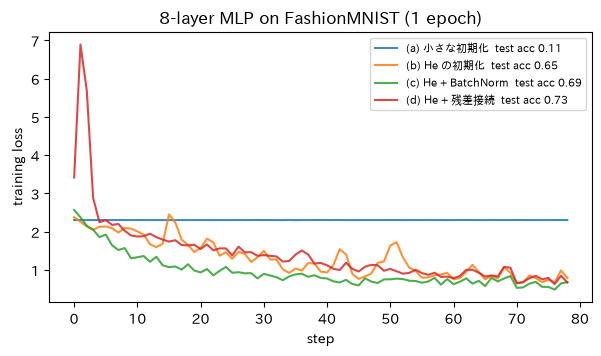

In [26]:
if HAS_HF:
    X_tr, y_tr, X_te, y_te = load_fashion_mnist(n_train=10000, n_test=2000)
    settings = {"(a) 小さな初期化": dict(init="small"), "(b) He の初期化": dict(init="he"),
                "(c) He + BatchNorm": dict(init="he", batchnorm=True), "(d) He + 残差接続": dict(init="he", residual=True)}
    plt.figure(figsize=(7, 3.5))
    for name, kw in settings.items():
        torch.manual_seed(0)
        losses, acc = train_model(DeepMLP(depth=8, **kw), X_tr, y_tr, X_te, y_te)
        plt.plot(losses, label=f"{name}  test acc {acc:.2f}", alpha=0.85)
        print(f"{name}: 最初の損失 {losses[0]:.2f} → 最後の損失 {losses[-1]:.2f}，テスト正解率 {acc:.2f}")
    plt.xlabel("step"); plt.ylabel("training loss"); plt.legend(fontsize=8); plt.title("8-layer MLP on FashionMNIST (1 epoch)"); plt.show()

読み方：(a) は損失が $\ln 10 \approx 2.30$ から動かない．§1 で見たとおり，小さな初期化では信号が層を通るたびに縮み，勾配も消える．(b) He の初期化で訓練が進み，(c) BatchNorm と (d) 残差接続はさらに速く安定に下がる．8 層でこの差なので，深いネットワークではこれらの技法が前提になる（第8回の ResNet，第10回の Transformer は (c)(d) に相当するものを両方持つ）．なお (d) では，足す側を $1/\sqrt{L}$ 倍に縮めている．縮めないと 8 層でも出力が膨らんで発散する（残差接続にも初期化の配慮が要る）．

**やってみよう 7-1**　`depth` を 8 から 16 や 32 にすると，(b) と (c)(d) の差はどうなるか．(b) が訓練できなくなる深さはどこか．

In [27]:
if HAS_HF:
    depth = 16   # TODO: 32 に変える
    for name in ("(b) He の初期化", "(d) He + 残差接続"):
        torch.manual_seed(0)
        losses, acc = train_model(DeepMLP(depth=depth, **settings[name]), X_tr, y_tr, X_te, y_te)
        print(f"depth {depth}, {name}: 最後の損失 {losses[-1]:.2f}，テスト正解率 {acc:.2f}")

depth 16, (b) He の初期化: 最後の損失 0.78，テスト正解率 0.46


depth 16, (d) He + 残差接続: 最後の損失 1.38，テスト正解率 0.51
